# Guía del prototipo de clasificación de células

Esta guía recorre el mismo código que usa la aplicación de Streamlit. Para ejecutar las celdas, abre JupyterLab desde la raíz del proyecto, instala las dependencias de notebook y prepara las imágenes según la [guía de reproducción](REPRODUCCION.md).

El [notebook de entrenamiento](PROYECTO_MALARIA_CNN.ipynb) explica cómo se obtuvo la CNN guardada. Aquí se usa para clasificar dos imágenes de prueba.

## 1. Cargar la CNN y elegir imágenes

El archivo de predicciones permite escoger un ejemplo por categoría y comprobar el resultado. Las imágenes se leen del dataset original.

In [1]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
from malaria_inference import (
    MODEL_PATH, THRESHOLD, decode_upload, grad_cam, load_model,
    parasitized_score, prepare_image, preview_image, render_grad_cam,
)

model = load_model()
reference_file = Path("results/metrics/predicciones_prueba.csv")
with reference_file.open(encoding="utf-8", newline="") as stream:
    references = list(csv.DictReader(stream))

targets = (0.10, 0.98)
examples = [min(references, key=lambda row: abs(float(row["prob_cnn"]) - target))
            for target in targets]
print(f"Modelo: {MODEL_PATH.relative_to(Path.cwd())}")
print(f"Entrada: {model.input_shape} · Salida: {model.output_shape}")

Modelo: models\modelo_malaria_cnn.keras
Entrada: (None, 48, 48, 3) · Salida: (None, 1)


## 2. Preparar la entrada y calcular las puntuaciones

La imagen se decodifica en tres canales RGB y se ajusta a 48 × 48 con relleno. La escala de píxeles se aplica dentro de la CNN. La salida corresponde a la clase **Parasitized**, cuyo umbral es 0,50.

In [2]:
analyses = []
for row in examples:
    path = Path(row["ruta"])
    if not path.is_file():
        raise FileNotFoundError("Prepara cell_images siguiendo REPRODUCCION.md.")
    rgb = decode_upload(path.read_bytes(), path.name)
    batch = prepare_image(rgb)
    score = parasitized_score(model, batch)
    positive = score >= THRESHOLD
    category = "Parasitized" if positive else "Uninfected"
    expected = float(row["prob_cnn"])
    assert int(positive) == int(row["pred_cnn"]) and abs(score - expected) < 2e-5
    analyses.append((rgb, batch, score, positive))
    print(f"{category} · Parasitized {score:.2%} · Uninfected {1 - score:.2%}")

Uninfected · Parasitized 10.00% · Uninfected 90.00%
Parasitized · Parasitized 98.00% · Uninfected 2.00%


## 3. Visualizar Grad-CAM

Se deriva el logit de la categoría predicha respecto a la activación de la última capa convolucional. El mapa se superpone a la imagen con sus proporciones originales. Las zonas claras indican mayor aporte a la predicción del modelo.

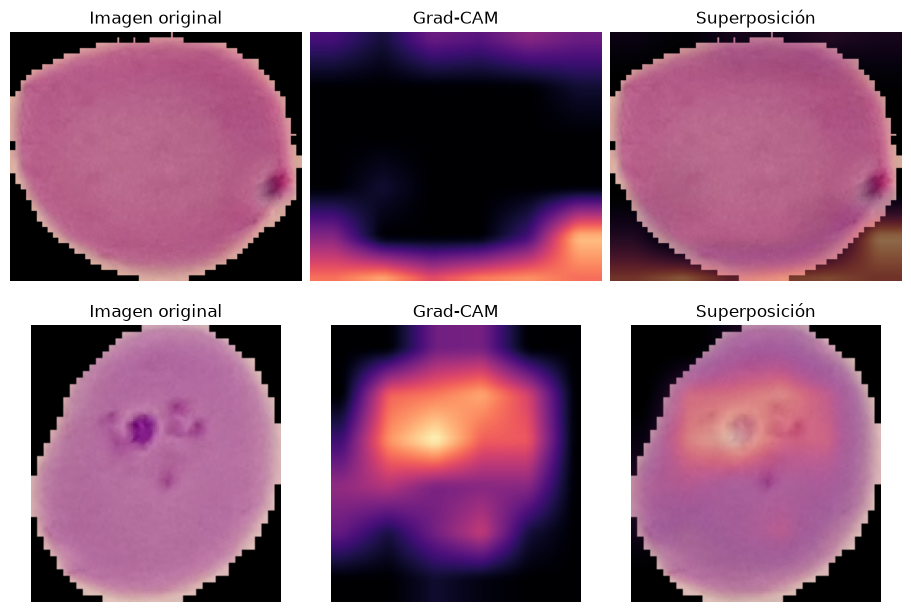

In [3]:
fig, axes = plt.subplots(2, 3, figsize=(9, 6), layout="constrained")
for ax_row, (rgb, batch, score, positive) in zip(axes, analyses):
    original = preview_image(rgb)
    heat = grad_cam(model, batch, positive)
    heatmap, overlay = render_grad_cam(heat, tuple(rgb.shape[:2]), original)
    for ax, image, title in zip(
        ax_row, (original, heatmap, overlay),
        ("Imagen original", "Grad-CAM", "Superposición"),
    ):
        ax.imshow(image)
        ax.set_title(title)
        ax.axis("off")
plt.show()

## 4. Conectar estas operaciones con Streamlit

En [app.py](app.py) están la carga del archivo, el botón de análisis y la presentación de resultados. El módulo [malaria_inference.py](malaria_inference.py) contiene las funciones que acabas de ejecutar. En la [arquitectura](ARQUITECTURA.md) se indica qué parte del proyecto realiza cada operación.

La [guía de reproducción](REPRODUCCION.md) explica cómo abrir el prototipo y ejecutar las pruebas. La [guía de publicación](PUBLICACION.md) describe el despliegue desde GitHub.

**Elaborado por Jaime Alejandro Galvez Egas**  
**Universidad Nacional Federico Villarreal 2026 ©**